# Frozen-model evaluation

Evaluate XGBoost at **threshold 0.62** on **104,034 test snapshots** from **5,558
customers**, with cutoffs June 6–October 17, 2011. Each row is one customer/week;
the outcome is purchase within the following 50 days. All sections use this test
population or slices of it.

No model fitting or threshold selection. See the [evaluation guide](../docs/evaluation.md)
for definitions, limitations and saved outputs.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from online_retail.modeling.evaluation import (
    load_evaluation, summarize, grouped_metrics, plot_overall, plot_weekly, plot_groups,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data/processed"
ARTIFACT = ROOT / "artifacts/final_roc_policy"
OUTPUT = ROOT / "artifacts/evaluation"
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Verify saved predictions

Check customer/cutoff alignment, observed outcomes, probabilities from the saved
pipeline and contact decisions at 0.62.

In [2]:
evaluation, frozen = load_evaluation(DATA, ARTIFACT)
threshold, costs = frozen["threshold"], frozen["costs"]
assert frozen["model"] == "xgboost" and threshold == 0.62
pd.Series({"model": frozen["model"], "threshold": threshold,
    "test_snapshots": len(evaluation), "distinct_customers": evaluation["Customer ID"].nunique(),
    "first_cutoff": evaluation.cutoff.min(), "last_cutoff": evaluation.cutoff.max(),
    "fit_last_cutoff": frozen["fit_last_cutoff"]})

model                             xgboost
threshold                            0.62
test_snapshots                     104034
distinct_customers                   5558
first_cutoff          2011-06-06 00:00:00
last_cutoff           2011-10-17 00:00:00
fit_last_cutoff       2011-01-10 00:00:00
dtype: object

## 2. Overall performance

ROC-AUC/AP measure ranking; log loss/Brier measure probability quality. Classification
metrics use 0.62. The reliability plot describes calibration; it does not recalibrate.

In [3]:
overall = pd.Series(summarize(evaluation, threshold, costs), name="test")
overall.to_csv(OUTPUT / "overall.csv")
overall.round(4)

snapshots                 104034.0000
customers                   5558.0000
buyers                     28186.0000
nonbuyers                  75848.0000
purchase_rate                  0.2709
mean_probability               0.4025
roc_auc                        0.7948
average_precision              0.6504
log_loss                       0.5098
brier_score                    0.1673
accuracy                       0.7962
precision                      0.7077
recall                         0.4224
f1                             0.5291
contact_rate                   0.1617
contacts                   16826.0000
mean_cost                      5.7657
total_cost                599830.0000
contact_none_mean_cost         6.7733
contact_all_mean_cost         13.6453
tn                         70929.0000
fp                          4919.0000
fn                         16279.0000
tp                         11907.0000
Name: test, dtype: float64

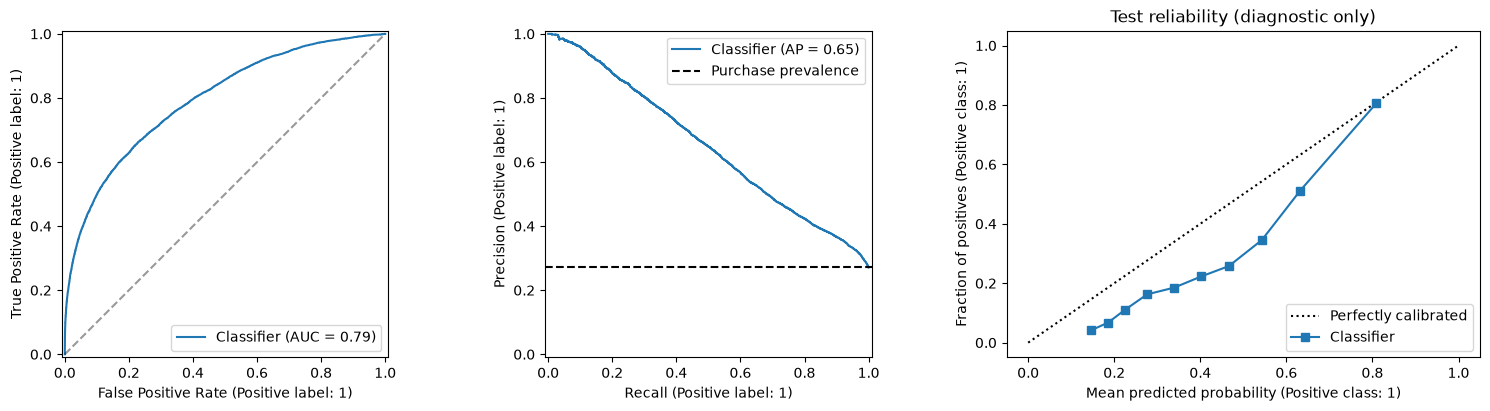

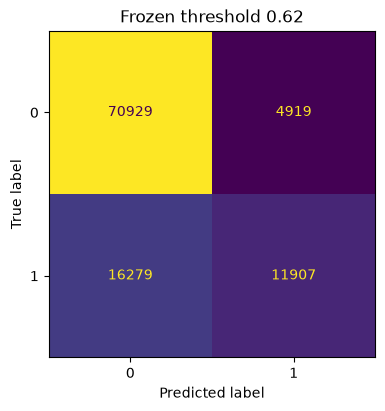

In [4]:
ranking_figure, confusion_figure = plot_overall(evaluation, threshold)
plt.show()

**Result:** precision **70.8%**, recall **42.2%**, ROC-AUC **0.795**.
Costs below use illustrative TN/FP/FN/TP values of £0/£15/£25/£10, not measured profit.

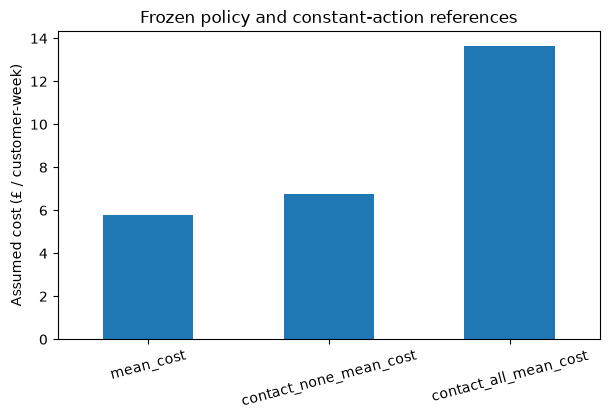

In [5]:
overall[["mean_cost", "contact_none_mean_cost", "contact_all_mean_cost"]].plot.bar(
    figsize=(7, 4), rot=15, ylabel="Assumed cost (£ / customer-week)",
    title="Frozen policy and constant-action references")
plt.show()

## 3. Performance by week

Compare ranking, probability bias, precision/recall, contact rates and assumed costs.
Counts show weekly denominators. Overlapping histories/outcomes make weeks correlated.

In [6]:
weekly = grouped_metrics(evaluation, "cutoff", threshold, costs)
weekly.to_csv(OUTPUT / "weekly_metrics.csv")
weekly[["snapshots", "buyers", "purchase_rate", "roc_auc", "average_precision",
        "precision", "recall", "contact_rate", "mean_cost"]].round(4)

,snapshots,buyers,purchase_rate,roc_auc,average_precision,precision,recall,contact_rate,mean_cost
cutoff,,,,,,,,,
2011-06-06,4951,1237,0.2498,0.8037,0.6497,0.7331,0.4042,0.1377,5.2828
2011-06-13,4977,1187,0.2385,0.8041,0.6402,0.7104,0.4153,0.1394,5.0824
2011-06-20,5005,1165,0.2328,0.8036,0.6350,0.6938,0.4163,0.1397,5.0070
2011-06-27,5030,1152,0.2290,0.8033,0.6356,0.6887,0.4245,0.1412,4.9264
2011-07-04,5049,1169,0.2315,0.8062,0.6375,0.7013,0.4098,0.1353,4.9713
2011-07-11,5065,1150,0.2270,0.8159,0.6427,0.7111,0.4174,0.1333,4.8322
2011-07-18,5088,1155,0.2270,0.8187,0.6503,0.7239,0.4199,0.1317,4.7907
2011-07-25,5116,1175,0.2297,0.8105,0.6405,0.7128,0.4162,0.1341,4.8857
2011-08-01,5143,1208,0.2349,0.8145,0.6482,0.7208,0.4338,0.1414,4.9358


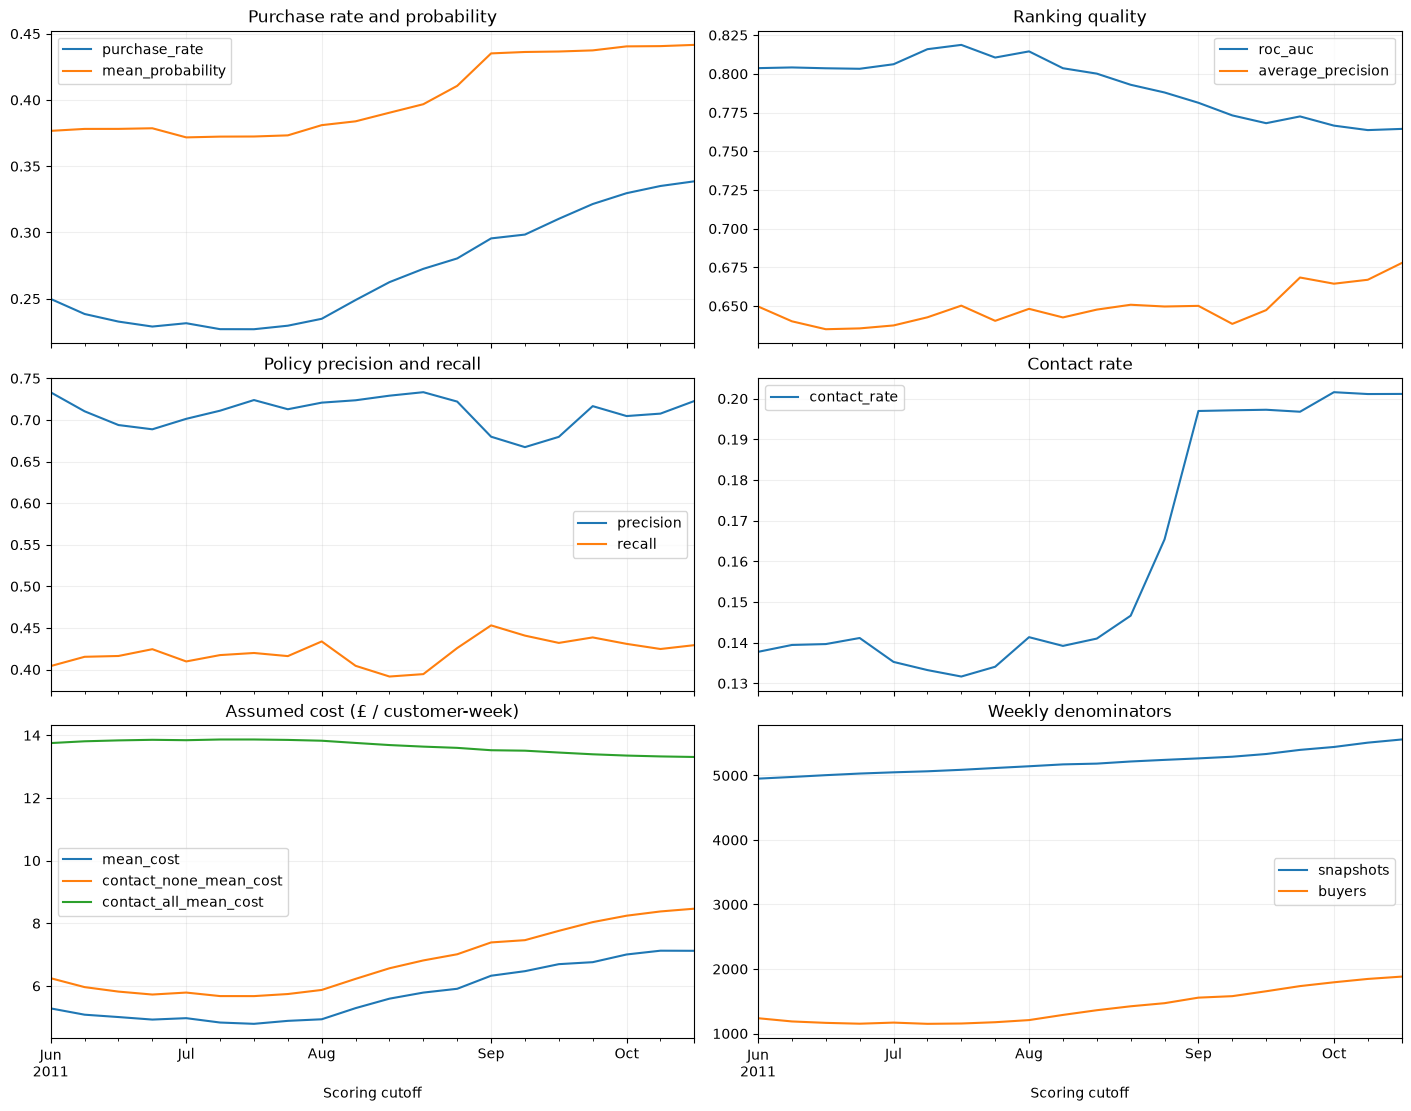

In [7]:
plot_weekly(weekly)
plt.show()

## 4. Performance by customer history

Invoice groups use past purchases at each cutoff: **1**, **2–3**, or **4+ invoices**.
Identity groups distinguish customers seen/unseen in the actual final fit. Unseen
customers still have purchase history. Customers can change invoice groups.

Compare counts and purchase rates alongside metrics. Missing values indicate
undefined metrics, such as precision when nobody is contacted.

In [8]:
group_columns = ["snapshots", "customers", "buyers", "nonbuyers", "purchase_rate",
    "roc_auc", "average_precision", "log_loss", "brier_score", "precision", "recall",
    "f1", "contact_rate", "mean_cost", "contact_none_mean_cost", "contact_all_mean_cost"]
history = grouped_metrics(evaluation, "history_group", threshold, costs)
identity = grouped_metrics(evaluation, "identity_group", threshold, costs)
history.to_csv(OUTPUT / "history_metrics.csv")
identity.to_csv(OUTPUT / "identity_metrics.csv")
history[group_columns].round(4)

,snapshots,customers,buyers,nonbuyers,purchase_rate,roc_auc,average_precision,log_loss,brier_score,precision,recall,f1,contact_rate,mean_cost,contact_none_mean_cost,contact_all_mean_cost
history_group,,,,,,,,,,,,,,,,
1 invoice,31661,2124,3233,28428,0.1021,0.7105,0.2387,0.3455,0.0956,NaN,0.0000,0.0000,0.0000,2.5528,2.5528,14.4894
2–3 invoices,28955,1877,5324,23631,0.1839,0.6510,0.3088,0.5177,0.1672,0.6528,0.0177,0.0344,0.0050,4.5740,4.5968,14.0806
4+ invoices,43418,2376,19629,23789,0.4521,0.7674,0.7582,0.6243,0.2196,0.7081,0.6018,0.6507,0.3842,8.9033,11.3023,12.7395


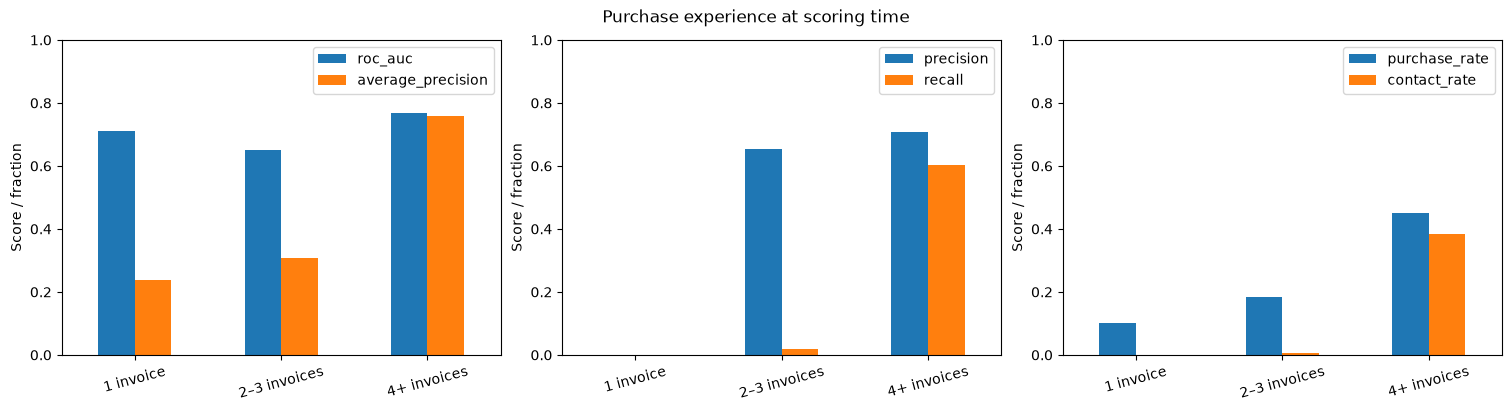

In [9]:
plot_groups(history, "Purchase experience at scoring time")
plt.show()

In [10]:
identity[group_columns].round(4)

,snapshots,customers,buyers,nonbuyers,purchase_rate,roc_auc,average_precision,log_loss,brier_score,precision,recall,f1,contact_rate,mean_cost,contact_none_mean_cost,contact_all_mean_cost
identity_group,,,,,,,,,,,,,,,,
Seen in final fit,87120,4356,23085,64035,0.2650,0.8213,0.6788,0.5044,0.1651,0.7051,0.4746,0.5673,0.1783,5.5270,6.6245,13.6751
Unseen in final fit,16914,1202,5101,11813,0.3016,0.7328,0.5682,0.5375,0.1787,0.7380,0.1866,0.2979,0.0763,6.9951,7.5396,13.4921


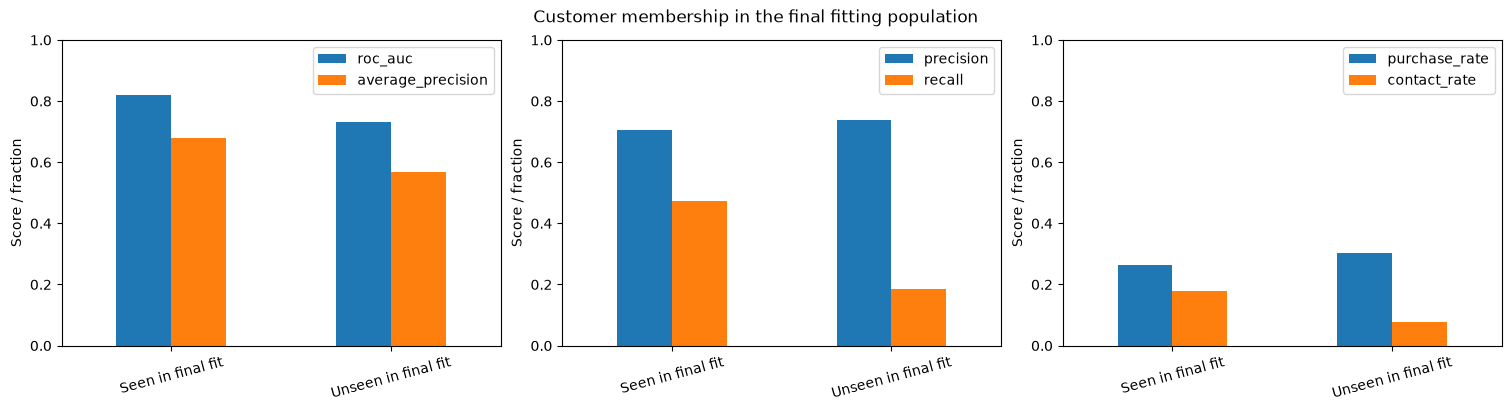

In [11]:
plot_groups(identity, "Customer membership in the final fitting population")
plt.show()

Tables are saved in `artifacts/evaluation/`. Definitions and limitations:
[evaluation guide](../docs/evaluation.md).

## Main findings

- Weekly ROC-AUC ranges **0.764–0.819**.
- Buyer recall is **0% / 1.8% / 60.2%** across the three invoice groups.
- Seen versus unseen customers have ROC-AUC **0.821 / 0.733** and recall **47.5% / 18.7%**.

The global metrics conceal substantial differences in coverage.

## SHAP explanations

Standard TreeExplainer on **5,000 sampled test snapshots** (seed 42). Contributions
are in **log-odds**, not probability points. Positive values push toward purchase.
The code verifies that contributions reconstruct predictions. Missing indicators
remain separate inputs. SHAP describes model behaviour, not causal effects.

In [12]:
import shap
from online_retail.modeling.explanations import explain_test, importance_summary

SHAP_OUTPUT = OUTPUT / "shap"
SHAP_OUTPUT.mkdir(parents=True, exist_ok=True)
shap_sample, shap_values, shap_features, shap_base = explain_test(
    evaluation, frozen["feature_columns"], ARTIFACT / "model.pkl", max_rows=5000, seed=42)
explanation = shap.Explanation(values=shap_values.to_numpy(),
    base_values=shap_base.to_numpy(), data=shap_features.to_numpy(),
    feature_names=shap_values.columns.tolist())
shap_importance, shap_by_history = importance_summary(shap_values, shap_sample)
shap_importance.to_csv(SHAP_OUTPUT / "global_importance.csv")
shap_by_history.to_csv(SHAP_OUTPUT / "history_importance.csv")
shap_sample[["Customer ID", "cutoff", "history_group"]].join(shap_values).join(shap_base).to_parquet(
    SHAP_OUTPUT / "sample_contributions.parquet", index=False)
shap_sample.groupby("history_group", observed=True).agg(
    snapshots=("Customer ID", "size"), customers=("Customer ID", "nunique"))

/home/gry-pho/Desktop/online_retail/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,snapshots,customers
history_group,,
1 invoice,1479,1013
2–3 invoices,1437,941
4+ invoices,2084,1407


### Group beeswarms

Each point is a snapshot: position shows SHAP contribution, color shows feature
value. Features rank separately within each group.

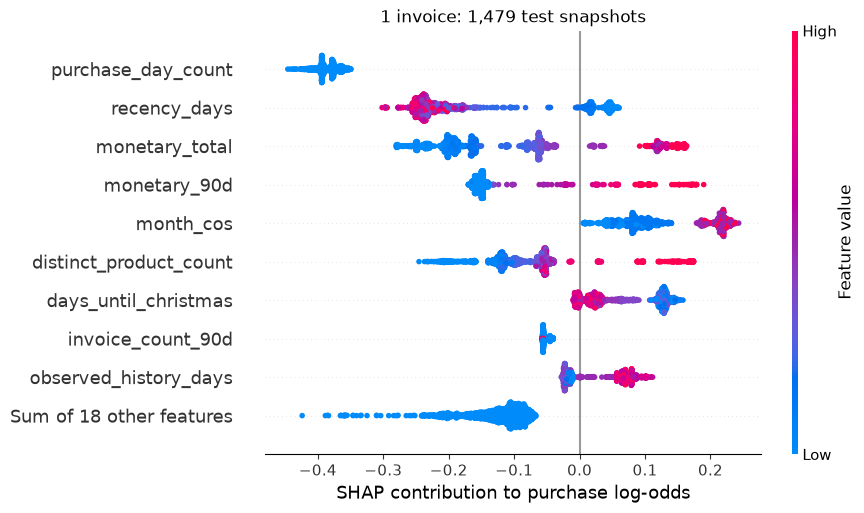

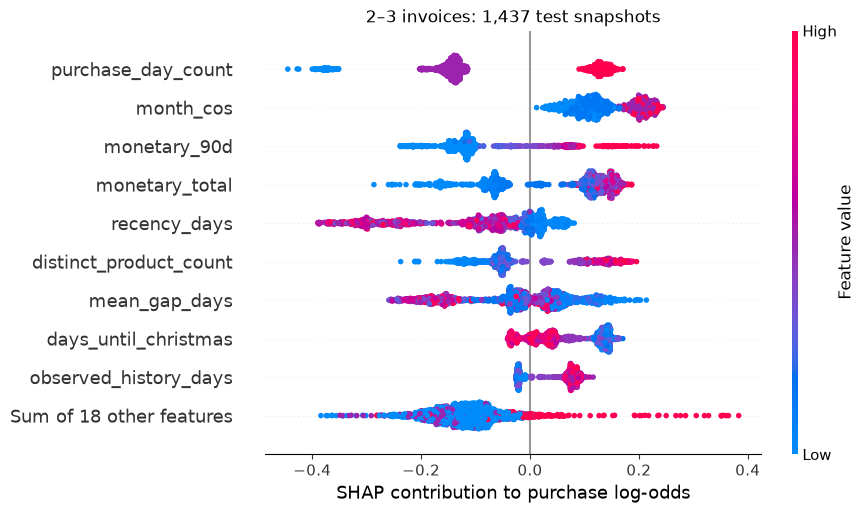

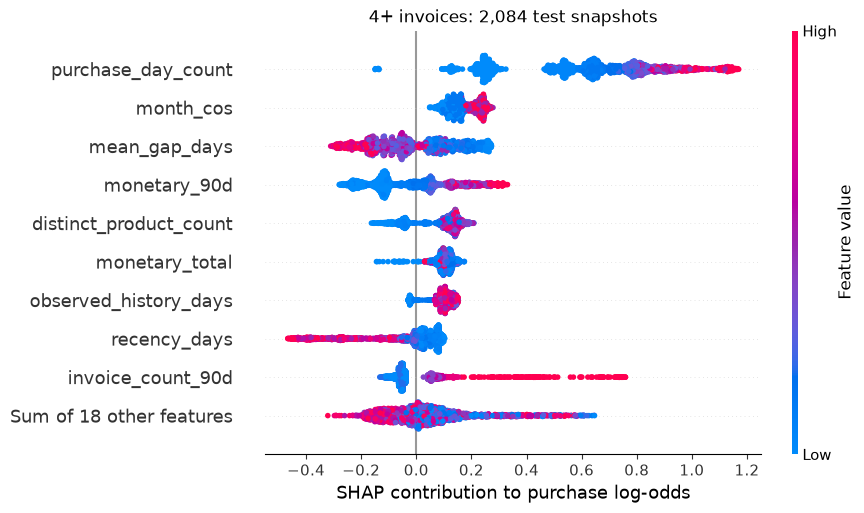

In [13]:
for group in shap_sample.history_group.cat.categories:
    positions = (shap_sample.history_group == group).to_numpy().nonzero()[0]
    if len(positions):
        shap.plots.beeswarm(explanation[positions], max_display=10, show=False)
        plt.title(f"{group}: {len(positions):,} test snapshots")
        plt.xlabel("SHAP contribution to purchase log-odds")
        plt.show()

### One waterfall per group

Choose the snapshot nearest each group's median predicted probability, without
using its outcome. Waterfalls explain the baseline-to-prediction change in log-odds;
titles show the resulting probability and contact decision.

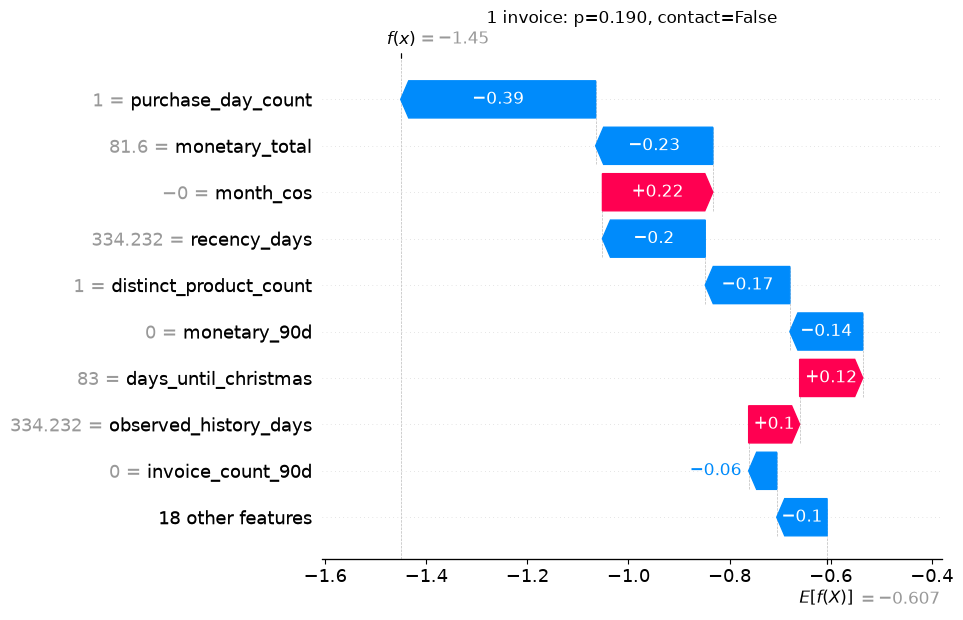

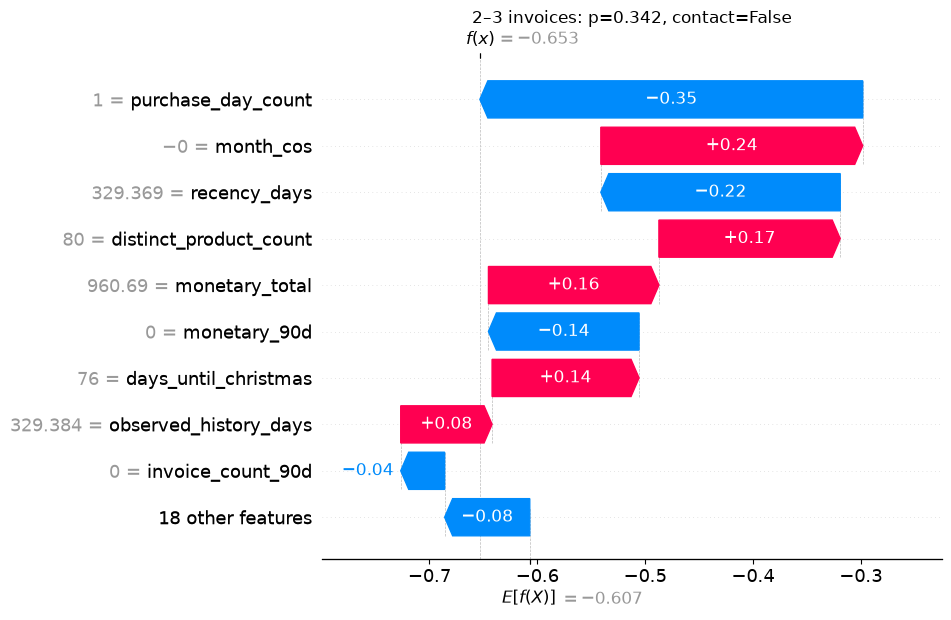

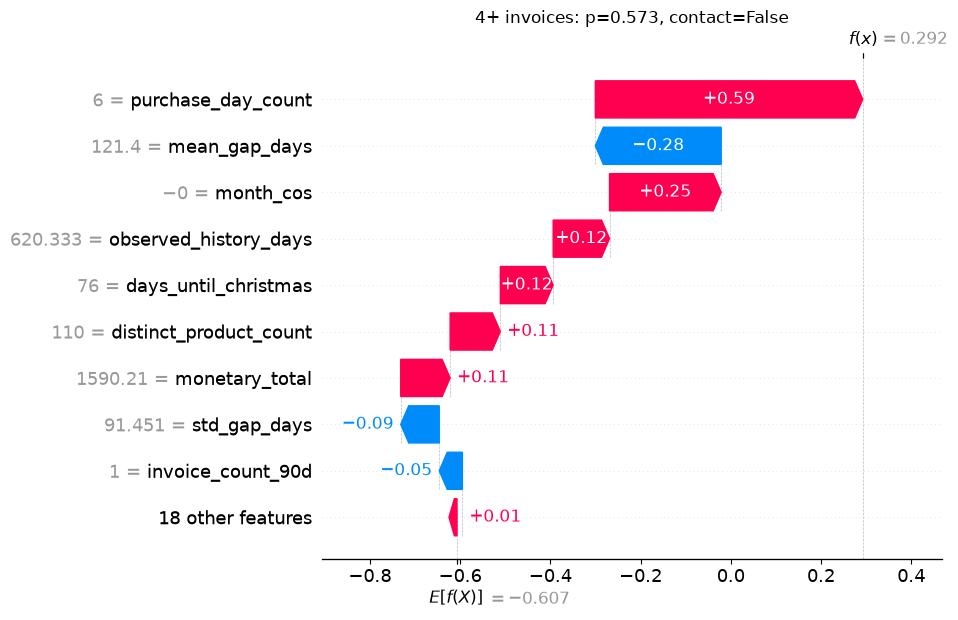

,history_group,Customer ID,cutoff,purchase_probability,actual_purchase,contact
0,1 invoice,13215,2011-10-03,0.189926,0,False
1,2–3 invoices,17544,2011-10-10,0.342260,0,False
2,4+ invoices,18016,2011-10-10,0.572574,1,False


In [14]:
example_rows = []
for group in shap_sample.history_group.cat.categories:
    positions = (shap_sample.history_group == group).to_numpy().nonzero()[0]
    if len(positions):
        probabilities = shap_sample.iloc[positions].p_class_1
        local_position = (probabilities - probabilities.median()).abs().to_numpy().argmin()
        position = positions[local_position]
        row = shap_sample.iloc[position]
        example_rows.append({"history_group": str(group), "Customer ID": row["Customer ID"],
            "cutoff": row.cutoff, "purchase_probability": row.p_class_1,
            "actual_purchase": row.RepurchaseWithin50Days,
            "contact": row.p_class_1 >= threshold})
        shap.plots.waterfall(explanation[position], max_display=10, show=False)
        plt.title(f"{group}: p={row.p_class_1:.3f}, contact={row.p_class_1 >= threshold}")
        plt.show()
examples = pd.DataFrame(example_rows)
examples.to_csv(SHAP_OUTPUT / "examples.csv", index=False)
examples

### The middle group

The **2–3 invoice group has the weakest ranking** (ROC-AUC **0.651**). At 0.62,
only **144** snapshots are contacted: **94 TP / 50 FP**, with **5,230 FN**.
Precision is **65.3%**, but recall is **1.8%**. Accuracy **81.8%** barely exceeds
the **81.6%** no-purchase baseline.

One-invoice recall is still worse (zero). No group is worst on every metric.

In [15]:
group_review = history[["snapshots", "purchase_rate", "roc_auc", "average_precision",
    "accuracy", "precision", "recall", "f1", "contacts", "tn", "fp", "fn", "tp"]].copy()
group_review["no_purchase_accuracy"] = 1 - group_review.purchase_rate
group_review.round(4)

,snapshots,purchase_rate,roc_auc,average_precision,accuracy,precision,recall,f1,contacts,tn,fp,fn,tp,no_purchase_accuracy
history_group,,,,,,,,,,,,,,
1 invoice,31661,0.1021,0.7105,0.2387,0.8979,NaN,0.0000,0.0000,0,28428,0,3233,0,0.8979
2–3 invoices,28955,0.1839,0.6510,0.3088,0.8176,0.6528,0.0177,0.0344,144,23581,50,5230,94,0.8161
4+ invoices,43418,0.4521,0.7674,0.7582,0.7078,0.7081,0.6018,0.6507,16682,18920,4869,7816,11813,0.5479


## Optional MLflow report import

Log these saved diagnostic tables without refitting or threshold selection.
The script `scripts/evaluate.py` can additionally generate and track PNG figures.
This import does not register or promote a model.

In [ ]:
IMPORT_EVALUATION = False
if IMPORT_EVALUATION:
    from online_retail.modeling.tracking import TrackingConfig
    from online_retail.modeling.workflows import import_results
    evaluation_run_id = import_results(
        OUTPUT, DATA, TrackingConfig.local(ROOT), name="evaluation-report-import")
    print(evaluation_run_id)